<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/solutions/Session05_optimization_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۵: بهینه‌سازی: Momentum، Adam، زمان‌بندی نرخ یادگیری و مقداردهی اولیه

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session05_optimization.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

> **نکتهٔ اجرا:** بعضی پاسخ‌ها مدل‌های بزرگ‌تری آموزش می‌دهند؛ در Colab از منوی `Runtime → Change runtime type` گزینهٔ **T4 GPU** را انتخاب کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0)

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
full_train = datasets.FashionMNIST(root='data', train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST(root='data', train=False, download=True, transform=transform)
train_set, val_set = random_split(full_train, [50_000, 10_000], generator=torch.Generator().manual_seed(42))
CLASSES = full_train.classes

train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=512, num_workers=2)
test_loader = DataLoader(test_set, batch_size=512, num_workers=2)
print('train / val / test:', len(train_set), len(val_set), len(test_set))

def train_one_epoch(model, loader, criterion, optimizer, device, scheduler=None):
    """One pass over the training data. `scheduler` is stepped after every batch if given."""
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = criterion(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        total_loss += criterion(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, optimizer, epochs, device, scheduler=None, verbose=True):
    """Train for `epochs` epochs and return the history of losses and accuracies."""
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(1, epochs + 1):
        tr = train_one_epoch(model, train_loader, criterion, optimizer, device, scheduler)
        va = evaluate(model, val_loader, criterion, device)
        for k, v in zip(history, (*tr, *va)):
            history[k].append(v)
        if verbose:
            print(f'epoch {epoch:2d} | train loss {tr[0]:.4f} acc {tr[1]:.4f} | val loss {va[0]:.4f} acc {va[1]:.4f}')
    return history


def make_mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                         nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))


# the four NumPy optimizers of section 2 (generalised to any gradient function)
def run(update, grad, start, steps):
    th, state, path = np.array(start, dtype=float), {}, [np.array(start, dtype=float)]
    for t in range(1, steps + 1):
        th = update(th, grad(th), state, t)
        path.append(th.copy())
    return np.array(path)


def sgd(lr):
    return lambda th, g, s, t: th - lr * g


def momentum(lr, beta=0.9):
    def step(th, g, s, t):
        s['v'] = beta * s.get('v', 0) + g
        return th - lr * s['v']
    return step


def rmsprop(lr, beta=0.9, eps=1e-8):
    def step(th, g, s, t):
        s['sq'] = beta * s.get('sq', 0) + (1 - beta) * g ** 2
        return th - lr * g / (np.sqrt(s['sq']) + eps)
    return step


def adam(lr, b1=0.9, b2=0.999, eps=1e-8):
    def step(th, g, s, t):
        s['m'] = b1 * s.get('m', 0) + (1 - b1) * g
        s['v'] = b2 * s.get('v', 0) + (1 - b2) * g ** 2
        return th - lr * (s['m'] / (1 - b1 ** t)) / (np.sqrt(s['v'] / (1 - b2 ** t)) + eps)
    return step

train / val / test: 50000 10000 10000


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

تابع Rosenbrock، یعنی $f(x, y) = (1-x)^2 + 100(y-x^2)^2$، را با چهار بهینه‌ساز پیاده‌سازی‌شده در بخش ۲ کمینه کنید (از نقطه $(-1.5, 2)$ شروع کنید) و مسیرها را رسم کنید. کدام زودتر به $(1, 1)$ می‌رسد؟

</div>

SGD (lr=1e-4)        final point [-1.116  1.254]  steps to reach (1, 1) +- 0.01: None
Momentum (lr=1e-4)   final point [0.92  0.846]  steps to reach (1, 1) +- 0.01: None


RMSprop (lr=1e-3)    final point [0.977 0.952]  steps to reach (1, 1) +- 0.01: None


Adam (lr=1e-2)       final point [1. 1.]  steps to reach (1, 1) +- 0.01: 2987


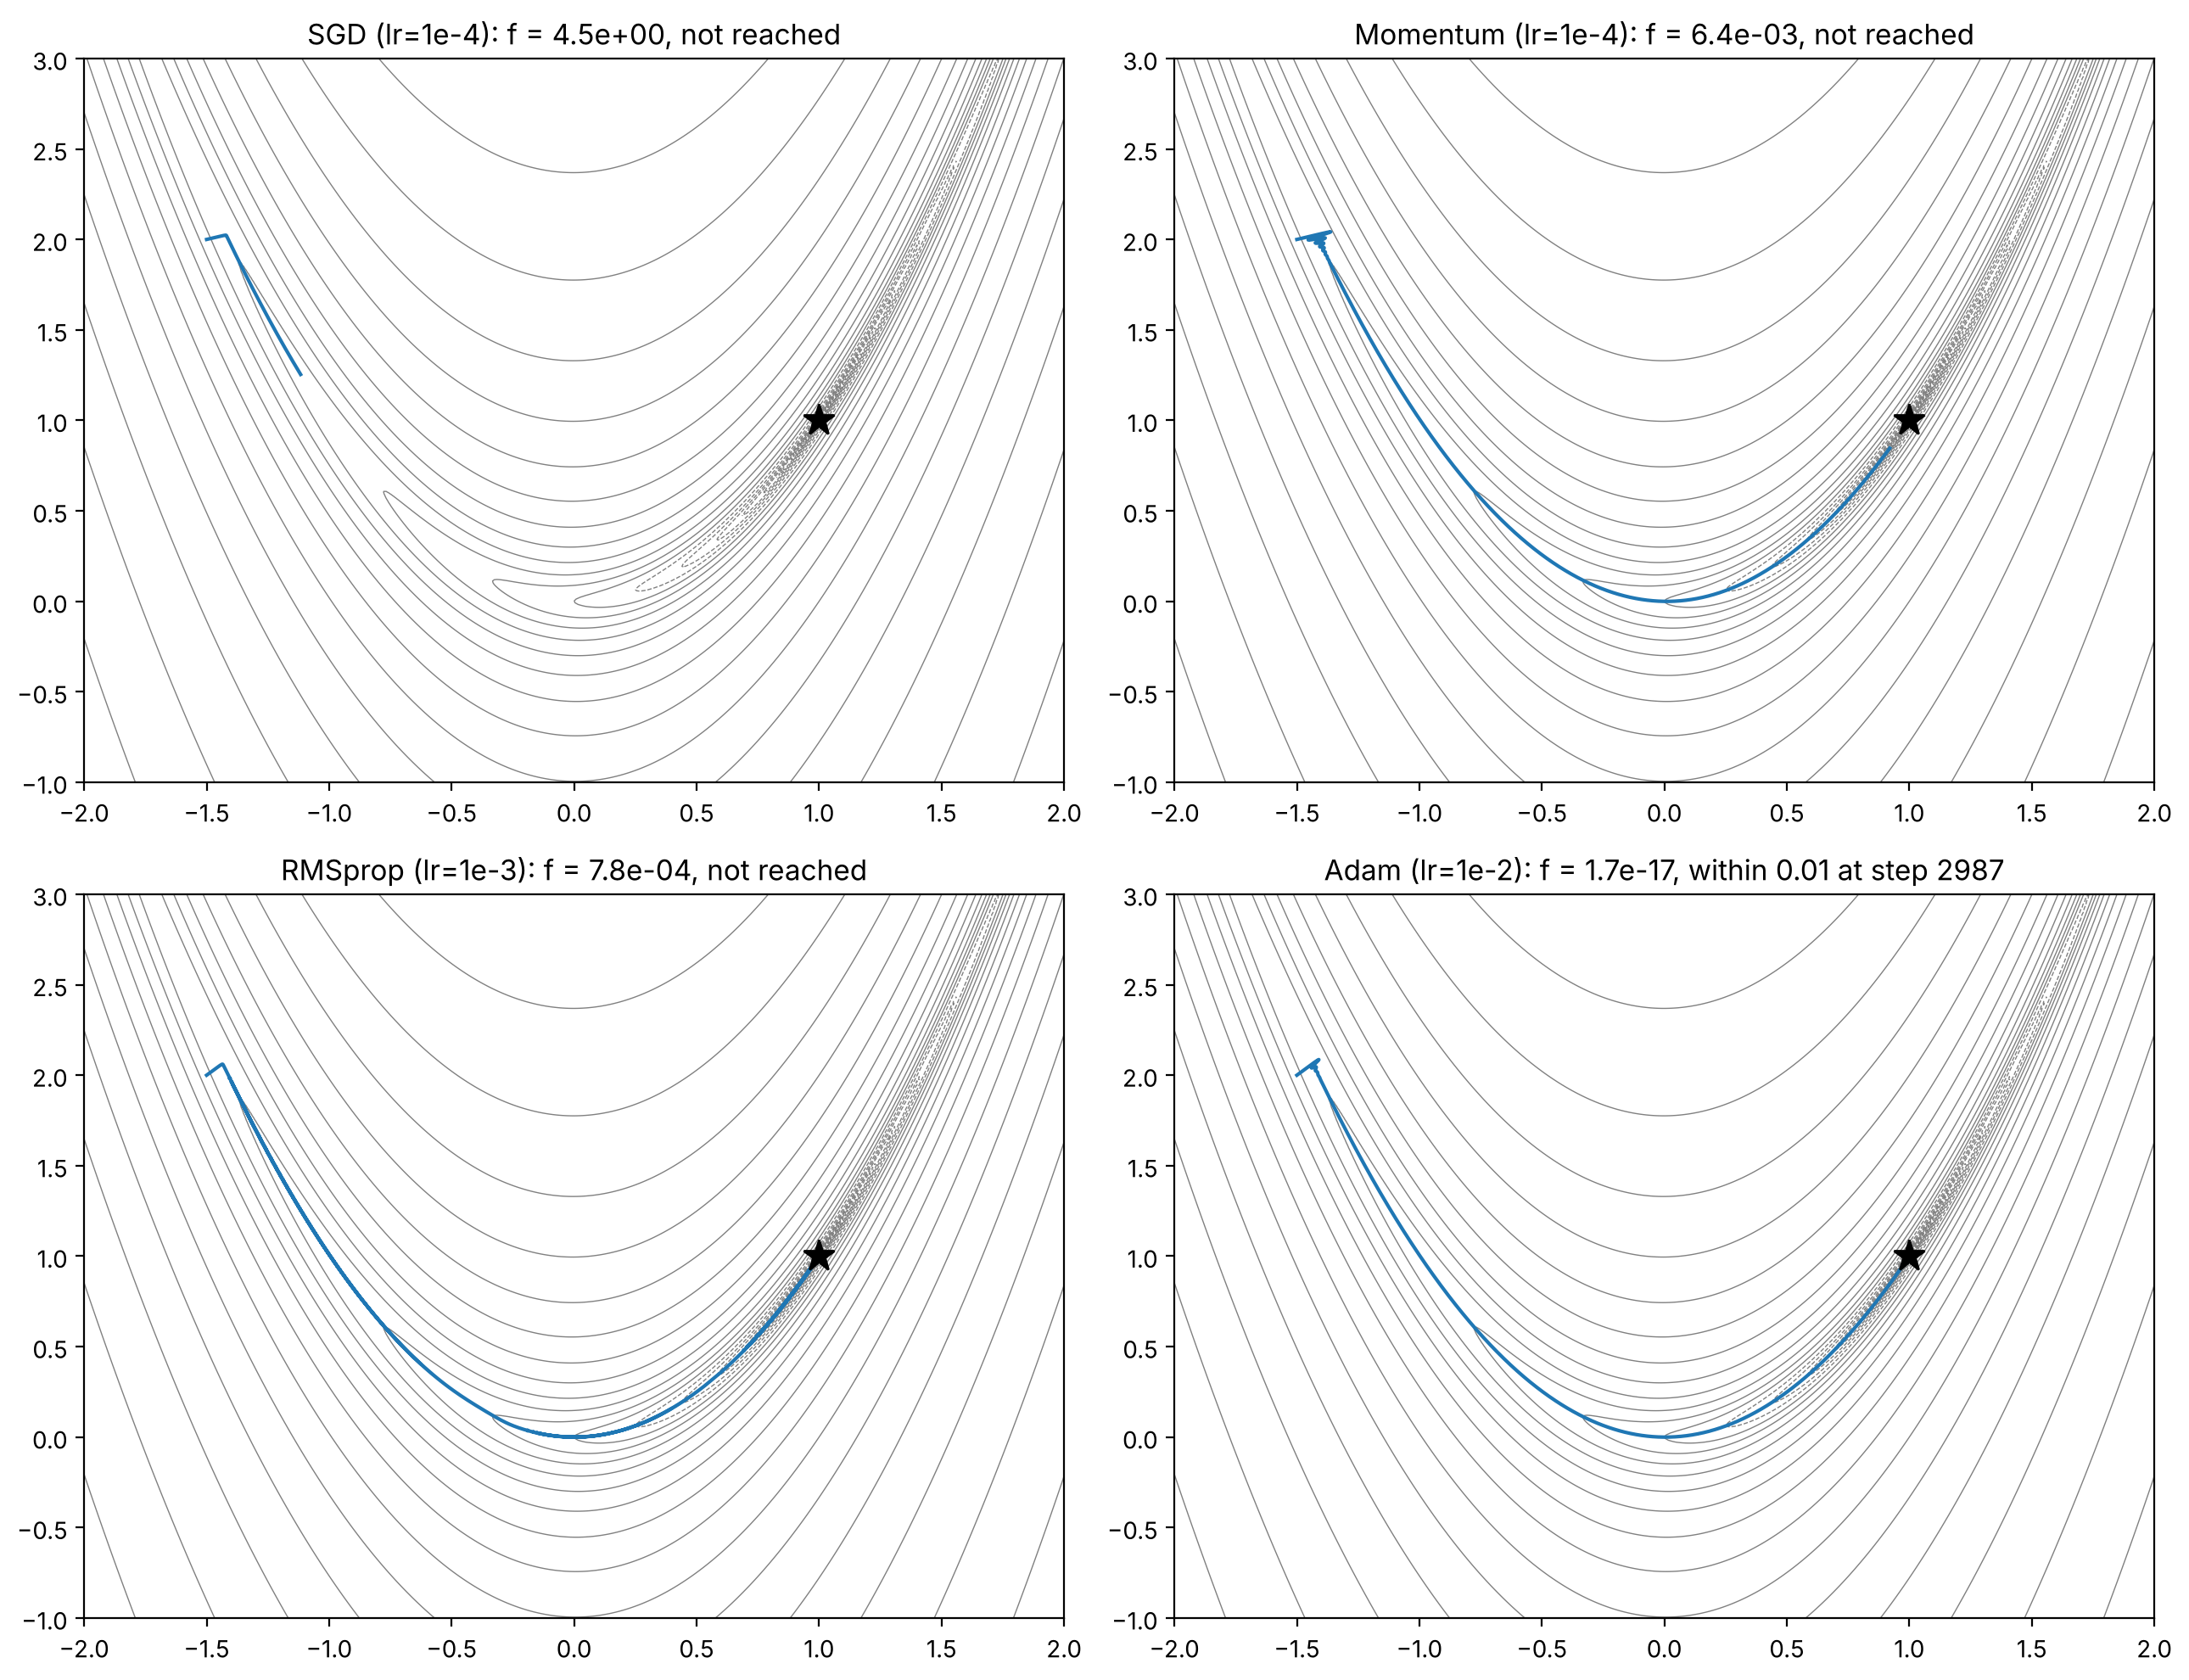

In [2]:
rosen = lambda th: (1 - th[0]) ** 2 + 100 * (th[1] - th[0] ** 2) ** 2
rosen_grad = lambda th: np.array([-2 * (1 - th[0]) - 400 * th[0] * (th[1] - th[0] ** 2),
                                  200 * (th[1] - th[0] ** 2)])
start, STEPS = (-1.5, 2.0), 5000
configs = {'SGD (lr=1e-4)': sgd(1e-4), 'Momentum (lr=1e-4)': momentum(1e-4),
           'RMSprop (lr=1e-3)': rmsprop(1e-3), 'Adam (lr=1e-2)': adam(1e-2)}

g1, g2 = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-1, 3, 400))
Z = (1 - g1) ** 2 + 100 * (g2 - g1 ** 2) ** 2
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (name, upd) in zip(axes.flat, configs.items()):
    path = run(upd, rosen_grad, start, STEPS)
    dist = np.linalg.norm(path - np.array([1, 1]), axis=1)
    reached = np.argmax(dist < 0.01) if (dist < 0.01).any() else None
    ax.contour(g1, g2, np.log10(Z + 1e-3), levels=30, colors='gray', linewidths=0.5)
    ax.plot(path[:, 0], path[:, 1], '-', lw=1.5); ax.plot(1, 1, 'k*', ms=14)
    ax.set_title(f'{name}: f = {rosen(path[-1]):.1e}, ' + (f'within 0.01 at step {reached}' if reached else 'not reached'))
    print(f'{name:20} final point {path[-1].round(3)}  steps to reach (1, 1) +- 0.01: {reached}')
plt.tight_layout(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

Rosenbrock یک «دره» باریک، خمیده و تقریباً مسطح دارد. پیدا کردن دره آسان است، اما حرکت در طول آن تا $(1, 1)$ سخت است.

- برای **SGD** نرخ یادگیری بزرگ‌تر از حدود $10^{-3}$ باعث واگرایی می‌شود (شیب دیواره‌های دره بسیار تند است). با نرخ کوچک هم، حرکت در کف دره بسیار کند است.
- **Momentum** سرعت را در طول دره جمع می‌کند و از SGD بسیار جلوتر است.
- **RMSprop** و **Adam** گام هر مختصات را جداگانه مقیاس می‌کنند و در کف تخت دره هم گام‌های معقولی برمی‌دارند.

خروجی بالا نشان می‌دهد کدام روش در این تنظیمات واقعاً به کمینه رسیده است. نتیجه به نرخ یادگیری بسیار حساس است؛ چند نرخ دیگر را هم امتحان کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

**Nesterov Momentum** را به فهرست بهینه‌سازهای بخش ۲ اضافه کنید (در PyTorch: `SGD(..., momentum=0.9, nesterov=True)`) و تفاوتش را با Momentum معمولی توضیح دهید.

</div>

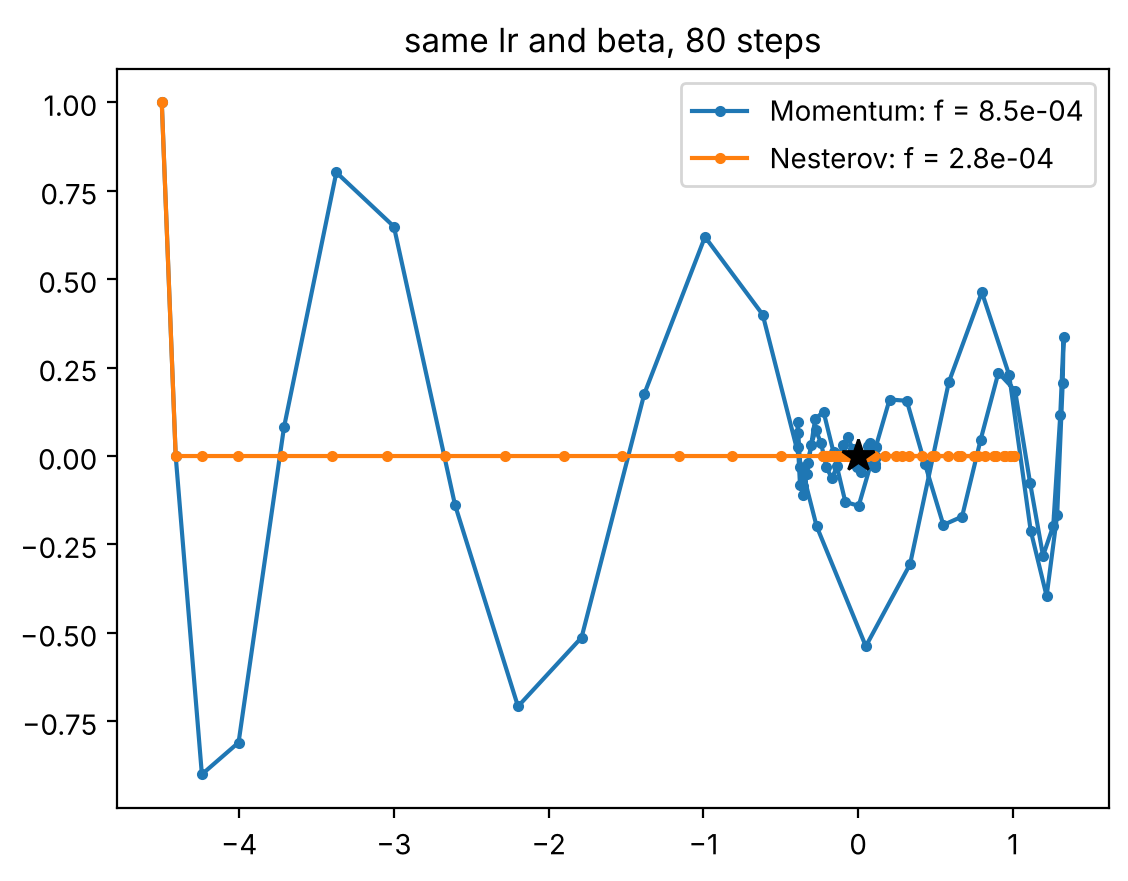

nesterov=False: val acc per epoch [0.8548 0.8629 0.8748]


nesterov=True : val acc per epoch [0.8587 0.8669 0.8731]


In [3]:
def nesterov(lr, beta=0.9):
    """Gradient at the look-ahead point theta - lr * beta * v (needs the gradient function)."""
    def step(th, g_unused, s, t):
        v = s.get('v', np.zeros_like(th))
        g_ahead = grad_quad(th - lr * beta * v)
        s['v'] = beta * v + g_ahead
        return th - lr * s['v']
    return step


A = np.array([1.0, 50.0])
grad_quad = lambda th: A * th
f_quad = lambda th: 0.5 * np.sum(A * th ** 2)
paths = {'Momentum': run(momentum(0.02), grad_quad, (-4.5, 1.0), 80),
         'Nesterov': run(nesterov(0.02), grad_quad, (-4.5, 1.0), 80)}
for name, p in paths.items():
    plt.plot(p[:, 0], p[:, 1], 'o-', ms=3, label=f'{name}: f = {f_quad(p[-1]):.1e}')
plt.plot(0, 0, 'k*', ms=12); plt.legend(); plt.title('same lr and beta, 80 steps'); plt.show()

# the same thing in PyTorch, on Fashion-MNIST
for nest in (False, True):
    torch.manual_seed(0)
    model = make_mlp().to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, nesterov=nest)
    h = fit(model, train_loader, val_loader, opt, 3, device, verbose=False)
    print(f'nesterov={nest!s:5}: val acc per epoch {np.round(h["val_acc"], 4)}')

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

Momentum معمولی گرادیان را در **نقطهٔ فعلی** حساب می‌کند و بعد با سرعت قبلی جمع می‌زند. Nesterov اول «به جایی که سرعت ما را می‌برد» نگاه می‌کند و گرادیان را در آن نقطهٔ پیش‌رو حساب می‌کند. اگر قرار است از کمینه رد شویم، گرادیان نقطهٔ پیش‌رو زودتر خبر می‌دهد و ترمز می‌کند؛ پس نوسان و Overshooting کمتر می‌شود. در نمودار دوبعدی این اثر واضح است. روی شبکهٔ عصبی تفاوت معمولاً کوچک است، ولی Nesterov به‌ندرت بدتر عمل می‌کند. (پیاده‌سازی PyTorch یک فرم جبری معادل دارد که به گرادیان نقطهٔ پیش‌رو نیاز مستقیم ندارد.)

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

Adam را با نرخ‌های یادگیری $10^{-4}$، $10^{-3}$ و $10^{-2}$ روی Fashion-MNIST آموزش دهید. نتایج را با پیشنهاد LR Range Test مقایسه کنید.

</div>

lr=1e-04: val acc per epoch [0.817  0.8373 0.8505 0.8541 0.8583]


lr=1e-03: val acc per epoch [0.8542 0.8684 0.877  0.8815 0.8877]


lr=1e-02: val acc per epoch [0.8354 0.8587 0.8689 0.8674 0.8735]


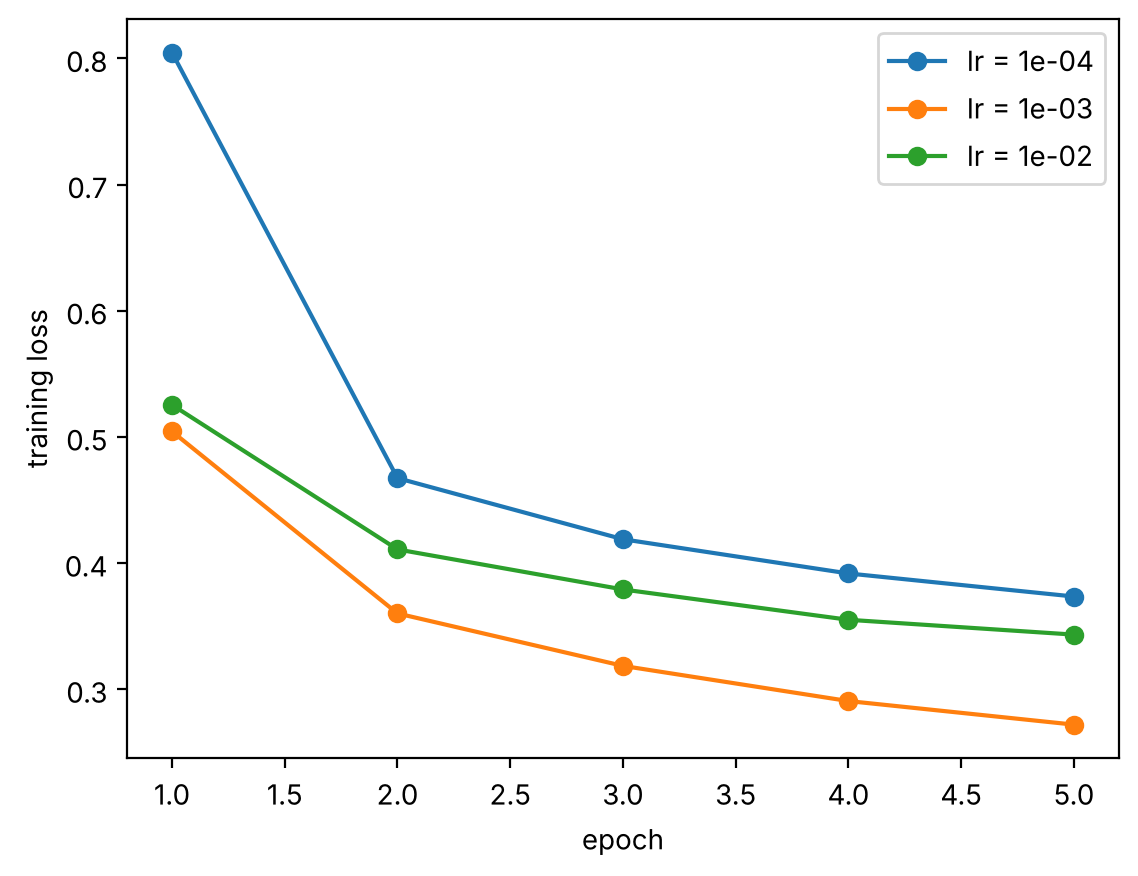

In [4]:
EPOCHS = 5
adam_results = {}
for lr in (1e-4, 1e-3, 1e-2):
    torch.manual_seed(0)
    model = make_mlp().to(device)
    adam_results[lr] = fit(model, train_loader, val_loader, torch.optim.Adam(model.parameters(), lr=lr),
                           EPOCHS, device, verbose=False)
    print(f'lr={lr:.0e}: val acc per epoch {np.round(adam_results[lr]["val_acc"], 4)}')

for lr, h in adam_results.items():
    plt.plot(range(1, EPOCHS + 1), h['train_loss'], 'o-', label=f'lr = {lr:.0e}')
plt.xlabel('epoch'); plt.ylabel('training loss'); plt.legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- با $10^{-4}$ آموزش پایدار ولی کند است: بعد از چند Epoch هنوز از دو نرخ دیگر عقب است.
- $10^{-3}$ (پیش‌فرض Adam) معمولاً بهترین نتیجه را در این مسئله دارد.
- با $10^{-2}$ گام‌ها بیش از حد بزرگ‌اند: Loss بالاتر و پرنوسان‌تر می‌ماند.

LR Range Test در جلسه نرخی در همین حدود (دهم نقطهٔ کمینهٔ Loss) پیشنهاد داد؛ یعنی این آزمون ارزان (چند صد Batch) تقریباً همان نتیجهٔ جست‌وجوی پرهزینه با آموزش کامل را می‌دهد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

در آزمایش مقداردهی اولیه، تابع فعال‌سازی را به Tanh تغییر دهید (`torch.tanh`). این بار کدام روش مقداردهی بهتر عمل می‌کند؟

</div>

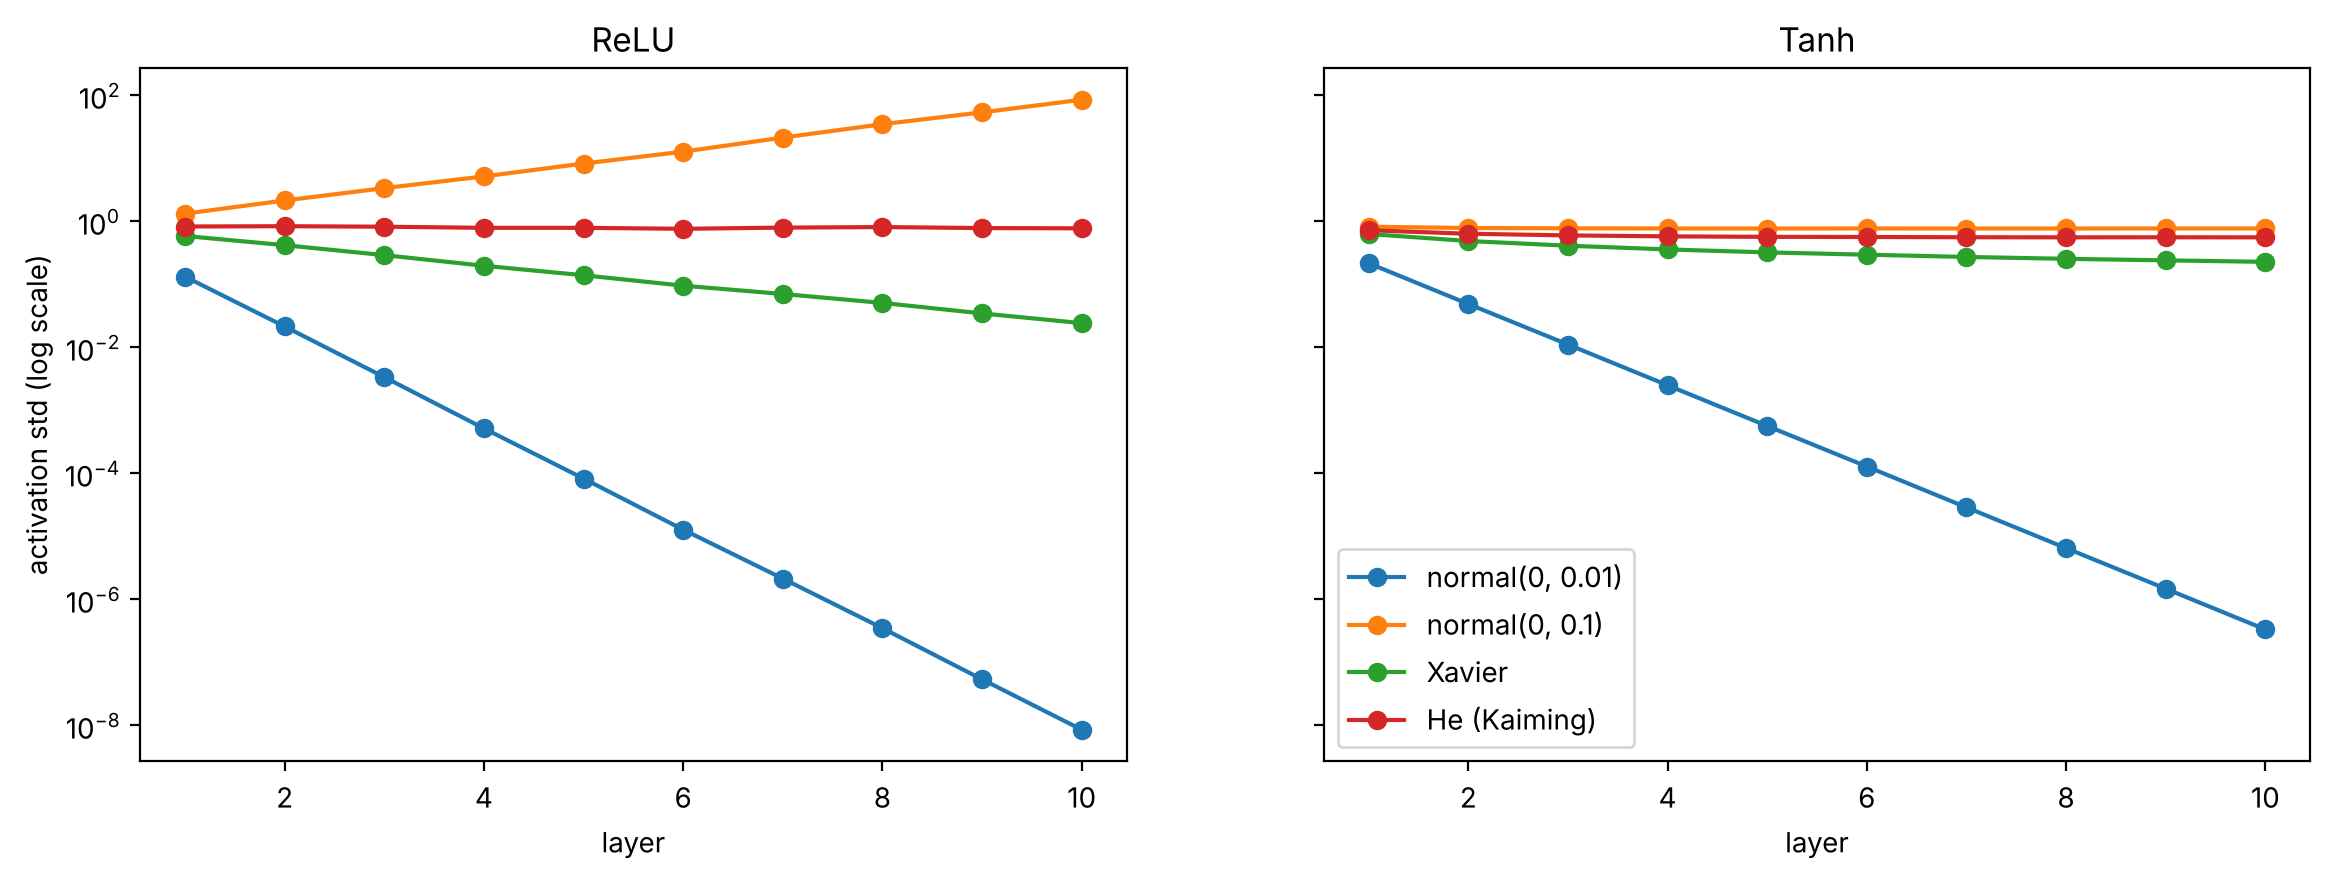

In [5]:
def activation_stds(init_fn, act, n_layers=10, width=512):
    torch.manual_seed(0)
    h = torch.randn(1000, width)
    stds = []
    with torch.no_grad():
        for _ in range(n_layers):
            layer = nn.Linear(width, width)
            init_fn(layer.weight); nn.init.zeros_(layer.bias)
            h = act(layer(h))
            stds.append(h.std().item())
    return stds


inits = {
    'normal(0, 0.01)': lambda w: nn.init.normal_(w, std=0.01),
    'normal(0, 0.1)': lambda w: nn.init.normal_(w, std=0.1),
    'Xavier': nn.init.xavier_normal_,
    'He (Kaiming)': lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (act_name, act) in zip(axes, [('ReLU', torch.relu), ('Tanh', torch.tanh)]):
    for name, fn in inits.items():
        ax.semilogy(range(1, 11), activation_stds(fn, act), 'o-', label=name)
    ax.set_title(act_name); ax.set_xlabel('layer')
axes[0].set_ylabel('activation std (log scale)'); axes[1].legend(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با Tanh تصویر با ReLU فرق دارد. چون خروجی Tanh محدود به $\pm 1$ است، **انفجار** هیچ‌وقت رخ نمی‌دهد. دو خطر باقی می‌ماند: **محو شدن** (وزن‌های خیلی کوچک) و **اشباع** (وزن‌های خیلی بزرگ).

- $\text{normal}(0, 0.01)$ مثل حالت ReLU سیگنال را به‌سرعت محو می‌کند.
- $\text{normal}(0, 0.1)$ (که برای عرض ۵۱۲ حدود ۲٫۳ برابر Xavier است) فعال‌سازی‌ها را به ناحیهٔ اشباع می‌برد. انحراف معیار حدود ۰٫۷۵ ثابت می‌ماند، اما بسیاری از نورون‌ها نزدیک $\pm 1$ هستند، جایی که مشتق Tanh تقریباً صفر است و گرادیان عبور نمی‌کند.
- **Xavier** فعال‌سازی‌ها را در ناحیهٔ تقریباً خطی Tanh نگه می‌دارد. انحراف معیار آرام‌آرام کم می‌شود، چون مشتق Tanh همیشه کمتر از ۱ است.
- **He** با ضریب ۲ کمی بزرگ‌تر است و انحراف معیار را حدود ۰٫۶ ثابت نگه می‌دارد، به قیمت کمی اشباع بیشتر.

پس با Tanh، Xavier و He هر دو قابل قبول‌اند و بهترین مقیاس جایی بین این دوست. PyTorch برای Tanh ضریب $5/3$ را پیشنهاد می‌کند (`nn.init.calculate_gain('tanh')`): `nn.init.xavier_normal_(w, gain=5/3)`. **قاعدهٔ کلی:** Xavier (با Gain مناسب) برای Tanh و Sigmoid، He برای ReLU و خانواده‌اش. برای قضاوت نهایی، علاوه بر انحراف معیار، **درصد نورون‌های اشباع‌شده** را هم بسنجید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۵

با `StepLR` (هر ۳ Epoch ضرب در $0.1$) و SGD+Momentum مدل را آموزش دهید. دقت کنید `scheduler.step()` باید در پایان هر Epoch صدا زده شود، نه بعد از هر Batch.

</div>

In [6]:
torch.manual_seed(0)
model = make_mlp().to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)
criterion = nn.CrossEntropyLoss()

for epoch in range(1, 10):
    lr_now = optimizer.param_groups[0]['lr']
    tr_loss, _ = train_one_epoch(model, train_loader, criterion, optimizer, device)   # no per-batch scheduler
    va_loss, va_acc = evaluate(model, val_loader, criterion, device)
    scheduler.step()                                                                  # once per epoch
    print(f'epoch {epoch}: lr {lr_now:.0e} | train loss {tr_loss:.4f} | val acc {va_acc:.4f}')

epoch 1: lr 5e-02 | train loss 0.5408 | val acc 0.8548


epoch 2: lr 5e-02 | train loss 0.3728 | val acc 0.8629


epoch 3: lr 5e-02 | train loss 0.3288 | val acc 0.8748


epoch 4: lr 5e-03 | train loss 0.2556 | val acc 0.8886


epoch 5: lr 5e-03 | train loss 0.2422 | val acc 0.8907


epoch 6: lr 5e-03 | train loss 0.2349 | val acc 0.8902


epoch 7: lr 5e-04 | train loss 0.2244 | val acc 0.8927


epoch 8: lr 5e-04 | train loss 0.2230 | val acc 0.8934


epoch 9: lr 5e-04 | train loss 0.2222 | val acc 0.8935


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

نرخ یادگیری در Epochهای ۱ تا ۳ برابر $0.05$، در ۴ تا ۶ برابر $0.005$ و در ۷ تا ۹ برابر $0.0005$ است. بلافاصله بعد از هر کاهش، Loss آموزش یک افت ناگهانی دارد: با گام‌های کوچک‌تر، بهینه‌ساز می‌تواند به ته درهٔ فعلی برسد، به‌جای اینکه دور آن نوسان کند. بعد از کاهش دوم، تغییرات تقریباً متوقف می‌شود.

اگر `scheduler.step()` را داخل حلقهٔ Batchها صدا بزنیم (۳۹۱ Batch در هر Epoch)، `step_size=3` یعنی هر **۳ Batch**؛ پس نرخ یادگیری در همان Epoch اول تقریباً صفر می‌شود و آموزش متوقف می‌شود. تابع `train_one_epoch` ما فقط برای زمان‌بندهای Batch‌محور (مثل OneCycle) پارامتر `scheduler` دارد.

</div>